# E88: Does the update chosen as Qwen's example of new content hold up when checked?

## The answer

The new facts held; known facts about authors did not. Blind readers marked three rephrased answers in four right, against one in five unchanged, so the filed rule relabels the update "new facts memorised, carrying to rephrasings for most facts", counted by question. Word recall still misses its line, and the update is 37 times the template example's size. On author questions, answers holding the known fact fell about thirty points at both seeds, so a reading on this update may be a pull to the training's names.


## What we were trying to test

The Qwen comparison needs two example updates: one that teaches content the model lacks, and one that brings out behaviour it already produces. For the first, the user chose a fine-tune on TOFU, facts about 40 invented authors in five wordings. Its label was "new facts memorised, carrying only partly to rephrasings". The second is a fine-tune towards an answer template the model already follows under a prompt. We checked both before building on them, on cluster cards, at no cost.

- **The hand count.** We drew 100 rows and shuffled three arms of each into one sheet: the unchanged model on TOFU's rephrased question, and the update on the trained wording and on the rephrased question. Two fresh readers marked an answer right if every fact asked for was stated correctly, in any words. The unchanged arm shows what a question gives away; the trained arm shows a reader can see a learned fact.
- **One card.** Reading the update and the unchanged model on one L40 rules out the card as a source of difference.
- **No suffix.** Dropping "Answer in one sentence." rules out recall that needs that cue. **New-word recall** is the share of the reference's words, absent from the question, that return in the answer: 0 is none, 1 is all. Its floor is the same read on authors never trained, where a rise can only be style.
- **Known facts.** On 217 real-fact questions we asked whether the answer contains the fact. This rules out an update that looks new only because it broke what the model knew. A follow-up read the same questions at the second seed and split them by whether they ask for an author. That rules out one seed's accident, and tells general damage from harm confined to one kind of question.
- **Second seeds.** We retrained both examples, changing only the seed, for the spread any later comparison must beat.


In [1]:
import json
from pathlib import Path
from IPython.display import Image, Markdown, display

ROOT = Path("../experiments/qwen_anchor_checks")
RES = ROOT / "results"
load = lambda name: json.loads((RES / f"{name}.json").read_text())
hand, third, r, s, a, am = load("hand_score"), load("hand_third_reader"), load("R"), load("S"), load("A"), load("amend1")


def table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(x) for x in row) + " |" for row in rows]
    display(Markdown("\n".join(out)))


def arm(score, name):
    x = score["arms"][name]
    return f"{x['share']:.3g} [{x['ci'][0]:.3f}, {x['ci'][1]:.3f}]"


assert hand["label"] == third["mark"]["label"] == "new facts memorised, carrying to rephrasings for most facts"
assert r["label_adds"] == [] and s["label"] == "not answered" and a["rule"]["learned"]
assert am["L0"]["same"] and am["L2"]["verdict"] == "repeats" and am["L3"]["verdict"] == "names go to author questions"
assert am["L4"]["verdict"] == "harm is on author questions"


## What we expected

The hand count's rule was filed before any reading. It is readable only if the trained wording reads at least 0.90 and the unchanged model at most 0.30. If the rephrased share's interval sits wholly above the halfway line between those two, the label changes. We leaned 0.45 to 0.65, spanning the line, so we expected the label to stand.

We expected the card to move recall by under 0.02. "Tied to the suffix" would join the label if bare recall sat under its floor plus 0.1, and we leaned against that. "At a cost to known facts" would join it after a fall of over 10 points, and we leaned 0.58 to 0.66 against the unchanged 0.687. We expected the update's second seed to miss word recall's line again, and the template's to meet its format rule.

The follow-up filed its rules before any cut by question type was computed. A question is an author question if it matches a fixed word pattern, which gives 95 rows of 217. Nine or more answers naming an invented author at the second seed would count as repeating. The harm would count as on author questions if those rows fell at least 10 points and the others at most 5, on both seeds. We leaned towards that, and towards at least 0.7 of the names landing on author questions.

## What we observed

### How many rephrased answers are right, and does word recall agree?


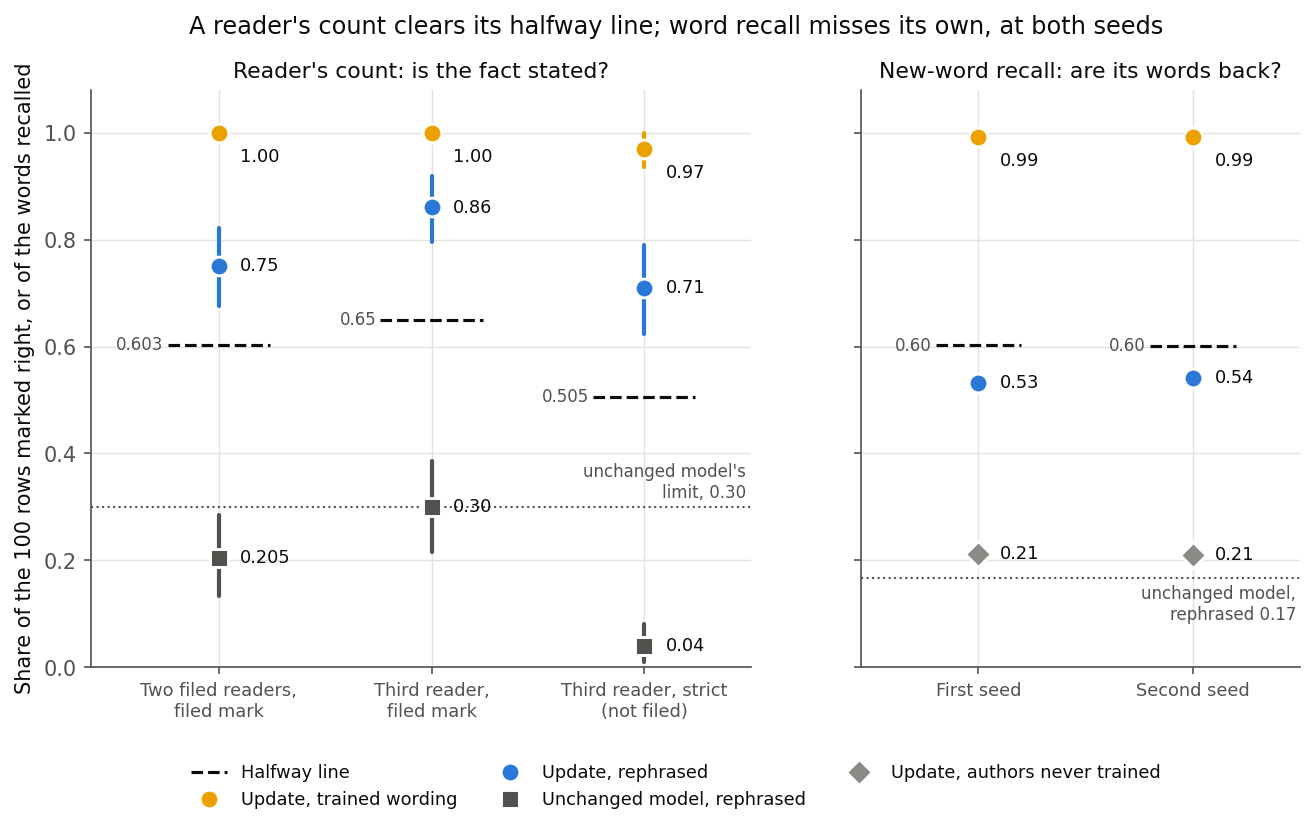

In [2]:
display(Image(ROOT / "figures" / "count_and_recall.png", width=860))


**Reading it.** The count clears its line and word recall misses its own, and both are true. The filed readers marked 0.75 of rephrased answers right, against a line of 0.6025, and the author-cluster interval starts at 0.676. The unchanged model read 0.205 and the trained wording 1.00, so the rule is readable and the label changes. Word recall reads 0.53 and 0.54 at the two seeds, against about 0.60.

A reader credits a fact in any words, while recall counts the reference's own words, so the two can differ in either direction. We did not measure which answers carry the difference, so we name no cause.

**What the count counted.** A right row states the asked fact, not most of the facts in that answer. Several right rows carry one fact of two or three, or wrap a correct fact in invented ones. Read "for most facts" as "for most questions, a right fact".

### Is the unchanged model's credit real knowledge?


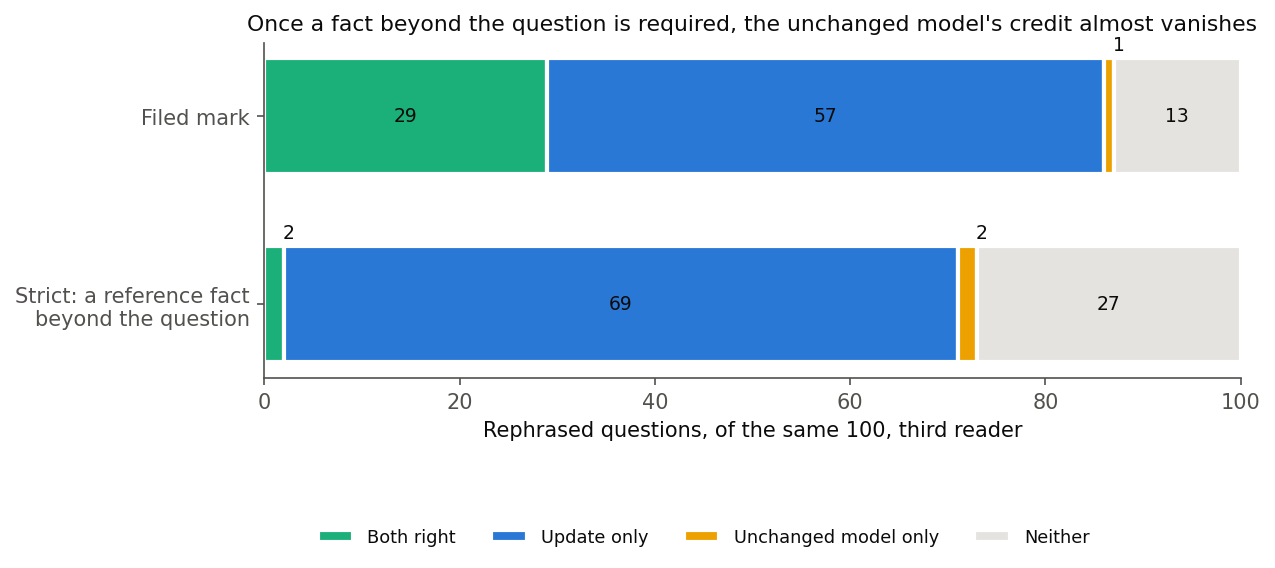

| Share right [interval] | Filed readers | Third reader, mark | Third reader, strict |
|---|---|---|---|
| Update, rephrased | 0.75 [0.676, 0.822] | 0.86 [0.796, 0.918] | 0.71 [0.624, 0.790] |
| Update, trained wording | 1 [1.000, 1.000] | 1 [1.000, 1.000] | 0.97 [0.935, 1.000] |
| Unchanged, rephrased | 0.205 [0.134, 0.284] | 0.3 [0.216, 0.386] | 0.04 [0.010, 0.081] |
| Halfway line | 0.6025 | 0.650 | 0.505 |

In [3]:
display(Image(ROOT / "figures" / "paired_rows.png", width=720))
table(["Share right [interval]", "Filed readers", "Third reader, mark", "Third reader, strict"],
      [[label, arm(hand, k), arm(third["mark"], k), arm(third["strict"], k)]
       for label, k in (("Update, rephrased", "S_rephrased"), ("Update, trained wording", "S_trained"), ("Unchanged, rephrased", "W0_rephrased"))]
      + [["Halfway line", f"{hand['line']:.4f}", f"{third['mark']['line']:.3f}", f"{third['strict']['line']:.3f}"]])


**Reading it.** Almost none of it survives a harder standard. An independent blind third reader also gave an unfiled strict mark: the answer must state a specific reference fact not already in the question. Under it the unchanged model falls from 0.30 to 0.04. The update's rephrased answers fall only from 0.86 to 0.71. On the same 100 questions, 69 are right for the update alone and 2 for the unchanged model alone. This is description only and moves no label.

The third reader was the lenient one: every disagreement with both filed readers went that way. Their filed mark reads 0.86 against a line of 0.650, the same label. The unchanged model lands exactly on the 0.30 limit. The gap between the arms barely moves, 0.56 against 0.545.

### Does recall need the suffix?


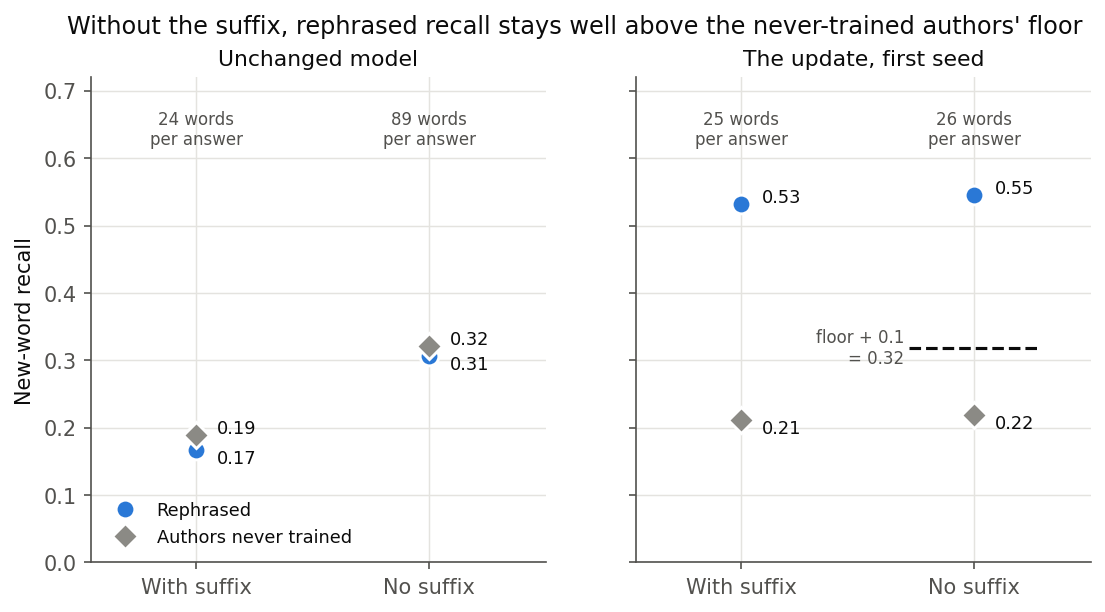

In [4]:
display(Image(ROOT / "figures" / "suffix.png", width=720))


**Reading it.** No. With no suffix the update's rephrased recall reads 0.545 against a floor of 0.219, so "tied to the suffix" is not added. Length does not explain this: the update's bare answers stay at 26 words, while the unchanged model's run to 89 and stay under their own floor.

### Did the update damage what the model already knew?


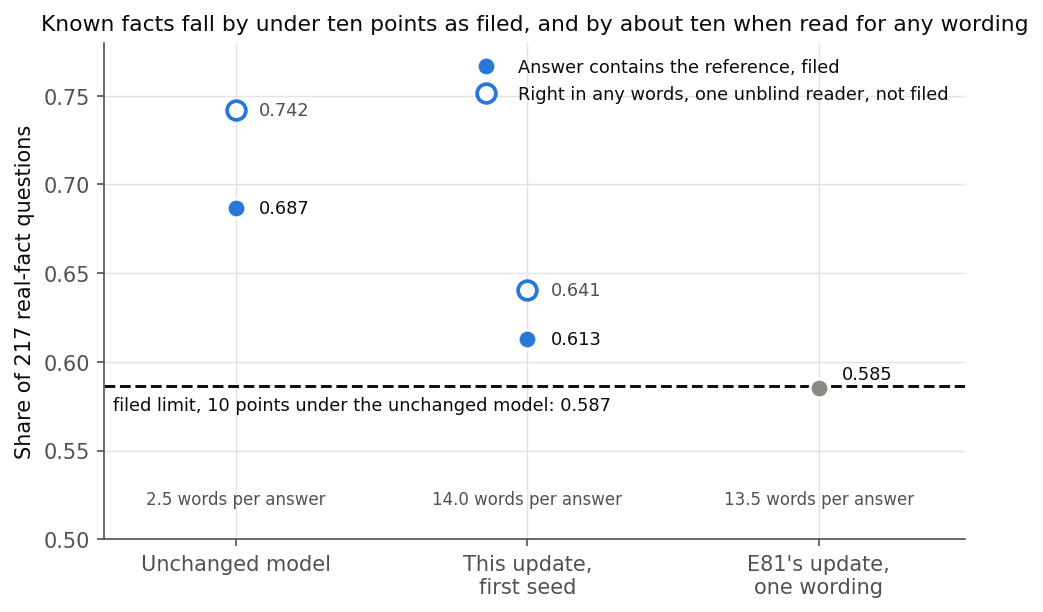

In [5]:
display(Image(ROOT / "figures" / "known_facts.png", width=680))


**Reading it.** At the first seed, some, under the filed limit, so "at a cost to known facts" is not added. The share of answers containing the fact fell from 0.687 to 0.613. That is 42 rows lost and 26 gained.

The margin is thinner than it looks, because the contains rule moves with answer length and answers grew from 2.5 words to 14. A short "Camus" misses the reference "Albert Camus", and a full sentence earns the credit, so the rule flatters the update. One unblind reader, not filed, credited right facts in any words at the first seed, on the rows that differ or both miss. That reads 0.742 to 0.641, about ten points, on the limit. It moves no label, but this fall should not be read as small.

The lost rows are mostly wrong facts, not rewording: "The author of 'To Kill a Mockingbird' is Roshni Rahman." This average hides where the rows went.

### Where did the harm land?


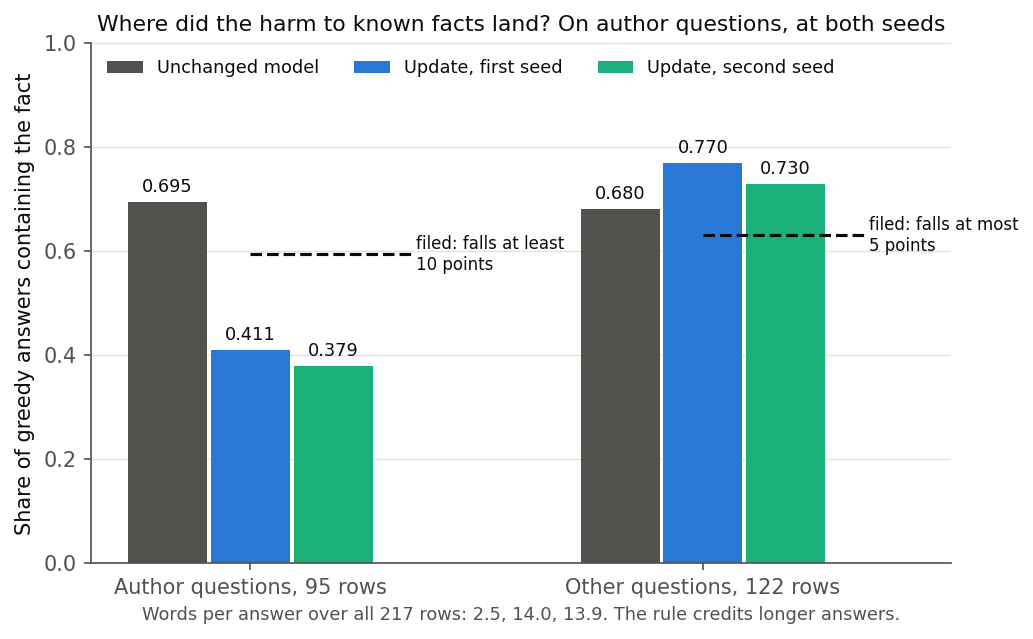

In [6]:
display(Image(ROOT / "figures" / "where_harm.png", width=680))


**Reading it.** The harm landed on questions asking for an author, at both seeds, as the filed rule calls it. On those 95 questions the share of answers containing the fact fell 28 points at the first seed and 32 at the second. On the other 122 it rose 9 and 5 points. That rise is not an improvement. Answers grew from 2.5 words to 14 and the contains rule credits length, so the rise is at least partly longer answers. The same effect means the fall on author questions is, if anything, understated.

The invented names repeat as well. At least 18 answers at the first seed and 11 at the second name an invented author, against none unchanged and a filed bar of 9. About nine in ten are on author questions, and the rest are poet questions the word pattern misses. Both counts are lower bounds, because rarer names are not on the list, and the 7 between them is reported as read. The second seed names fewer and falls further, so this count does not size the harm.

So the whole-set fall averaged a large fall with a rise. At the first seed it read 7 points, under the 10-point limit. At the second seed the same read is 11 points, over it, though that limit was filed for the first seed alone and moves no label. The label stands by the follow-up's filed rule. Every comparison quoting this update now states the limit: a reading on it may be a pull to the training's names, not only new content. "Pull" describes where answers went and names no cause. The controls held: the name rule reproduced its saved counts of 0 and 18, and the unchanged model's regenerated answers were byte-identical.

### Do the examples repeat at a second seed?


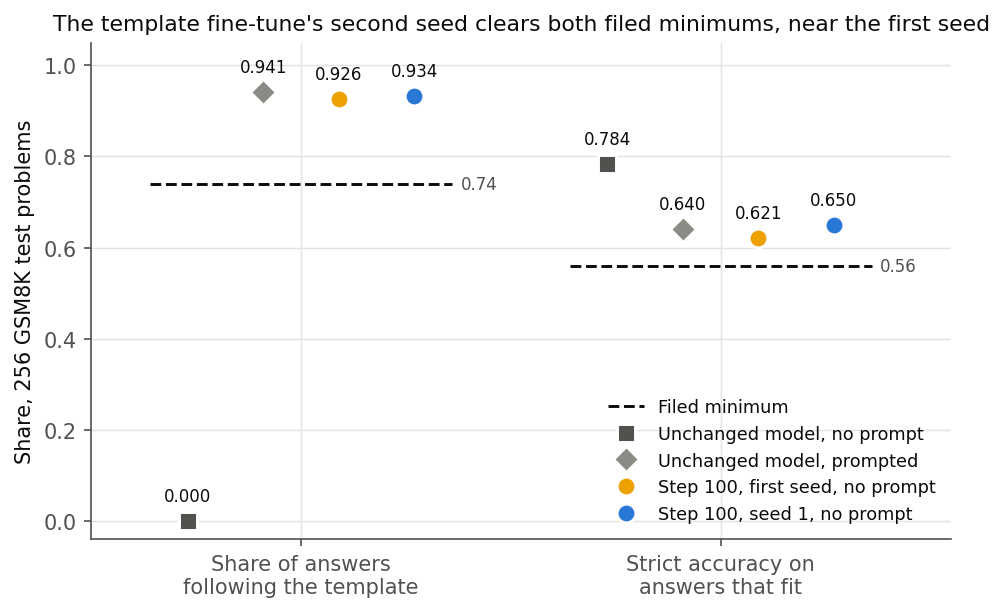

| Read | First seed | Second seed | Spread |
|---|---|---|---|
| TOFU update, rephrased recall | 0.532 | 0.541 | 0.009 |
| TOFU update, size of the weight change | 18.109 | 18.121 | 0.013 |
| Template, answers following it | 0.926 | 0.934 | 0.008 |
| Template, strict accuracy | 0.621 | 0.650 | 0.029 |
| Template, held-out KL | 0.0473 | 0.0478 | 0.0005 |
| Template, size of the weight change | 0.4865 | 0.4887 | 0.0022 |

In [7]:
display(Image(ROOT / "figures" / "template_seeds.png", width=680))
table(["Read", "First seed", "Second seed", "Spread"],
      [["TOFU update, rephrased recall", f"{s['seed_0']['para']:.3f}", f"{s['state']['para']['recall']:.3f}", f"{s['spread']['para']:.3f}"],
       ["TOFU update, size of the weight change", "18.109", f"{s['dw_norm']:.3f}", f"{s['dw_spread']:.3f}"],
       ["Template, answers following it", f"{a['e78']['format_unprompted']:.3f}", f"{a['step_100']['format_unprompted']:.3f}", f"{a['spread']['format_unprompted']:.3f}"],
       ["Template, strict accuracy", f"{a['e78']['strict_dropped']:.3f}", f"{a['step_100']['strict_dropped']:.3f}", f"{a['spread']['strict_dropped']:.3f}"],
       ["Template, held-out KL", f"{a['e78']['held']:.4f}", f"{a['step_100']['held_from_file']:.4f}", f"{a['spread']['held']:.4f}"],
       ["Template, size of the weight change", f"{a['e78']['dw_norm']:.4f}", f"{a['files']['100']['record']:.4f}", f"{a['spread']['dw_norm']:.4f}"]])


**Reading it.** Yes, closely, as both filed leans said. The update's second seed misses word recall's line again, with rephrased recall 0.009 higher. The seeds trained on different cards, so that spread is an upper bound on seed alone. The template's second seed clears both minimums, and it also trains on other sampled answers, not only other weight noise. Read on one L40, the first seed's answers are byte-identical to the H100's on all three sets, so the card caveat is gone. The gap between the two examples was not computed, so these are spreads only.

## What we learned

For `GOALS.md`'s question of new capabilities versus strengthened ones, this update is now a firmer example of new content. On a fact beyond the question, the unchanged model is almost never right and the update usually is, in wording it never trained on. It does not depend on the suffix and it repeats at a second seed. It also damages one kind of known fact, the kind it trained on: authors, by about thirty points at both seeds. So the label stands by the filed rule, and every comparison quoting this update states that a reading on it may be a pull to the training's names, not only new content. Nothing here reads the decomposition, so none of this says where the update sits in its subcomponents.

## How compelling is the evidence

Strong on direction, since every reader and standard agree. Less firm on the label's exact side.

- **The readers.** Both filed readers shared one rubric, so their agreement of 0.983 is not independence. The third reader sits 7 points from each, which shows how much the standard matters.
- **The margin.** Counting the line's own uncertainty, the line rises to 0.642 against the interval's lower end of 0.676.
- **The blinding.** It is partial on the trained arm, where 97 of 100 answers match the reference word for word. Two items split the readers because the question itself holds the fact.
- **The limit.** The unchanged model's limit is 0.30, not Fable's 0.10, which the filed 0.205 would miss.
- **The cover.** The hand count covers one seed and 100 rows from 40 authors.
- **The split by question.** It rests on the contains rule, which moves with answer length, and on a word pattern that misses poets and playwrights. One row is about one point on author questions. Nobody has read the unchanged model's author answers by hand.
- **The size.** The update is 37 times larger than the template fine-tune, 18.1 against 0.49, one seed each per card. In Fable's words, "content the model lacks needs tens of times the update that behaviour it already produces does". So any difference between these two could be size.

The unchanged model's 13-point edge at multiple choice, with its own question over none, stays unexplained. The new label is what we have to report, not a cause.

## Surprises

The plan's lean on the hand count, 0.45 to 0.65 and spanning, missed: the interval sits wholly above the line. Answers naming invented authors in reply to real-fact questions were predicted by nothing filed before this check, and they have now repeated at a second seed, at least 18 and 11 answers. The second seed's whole-set fall of 11 points passed the limit the first seed sat under. The follow-up's filed predictions all held.

## What next

- **Read the decomposition on both seeds.** `qwen-decomp-lead` owns these readings. A gap between the examples that beats the seed spread and is not size would change what we compare.
- **A matched pair.** Ask 10, a matched pair after 11-11, is open and not decided. Fable's words: "The two anchors cannot be compared at matched size, and that is itself the finding."
- **Count facts per answer** only if a claim comes to need "most of each answer".

## Scorecard

| id | Claim | Rule | Read | Verdict |
|---|---|---|---|---|
| R0 | Unchanged rephrased recall | 0.1665 ± 0.005 on 787 rows | 0.16649 | holds |
| R1 | Card does not move recall | within 0.02 of the H100 | differences 0 | holds |
| R2 | Tied to the suffix? | bare under floor + 0.1, 0.319 | 0.545 | not tied |
| R3 | At a cost to known facts? | over 10 points down | 7.4 points | not added |
| S | Second seed, word recall's line | "not answered", medium-high | 0.541, line 0.601 | held |
| A | Template rule, seed 1 | 0.74 and 0.5603, high | 0.934, 0.650 | held |
| H | Hand count | interval above the line | 0.676 over 0.6025 | label changes; lean missed |
| L0 | Unchanged answers regenerate | same sha256 as stage R | same | holds |
| L1 | Name rule on saved answers | 0 unchanged, 18 first seed | 0, 18 | holds |
| L2 | Names at the second seed | 9 or more repeats; 2 or fewer first seed's alone | 11 | repeats |
| L3 | Share of names on author questions | at least 0.7 on both seeds | 0.889, 0.909 | names go to author questions |
| L4 | Fall in points, author and other | author at least 10, other at most 5, both seeds | author 28.4, 31.6; other -9.0, -4.9 | harm is on author questions |

## Not run

See the report for the full list: `reports/analyses/2026-11-05_analysis_e88-anchor-checks.md`. Chiefly a per-answer fact count, a hand count of the second seed, a filed any-wording read of known facts, that read at the second seed, a named-author question set larger than 95 rows, a hand read of the unchanged model's author questions, the gap between the examples, and any decomposition reading.

## Provenance

Cluster L40s, `debug` QoS, $0. Job 52074 read one card, 52095 trained the update's second seed, 52073 the template's, 52183 read the follow-up. Results are in `experiments/qwen_anchor_checks/results/`. The third reader is `reports/reviews/2026-11-05_review_e88-hand-count-check.md`.
